<a href="https://colab.research.google.com/github/hilalkaynarcali/goruntu-isleme/blob/main/DFT_analizi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

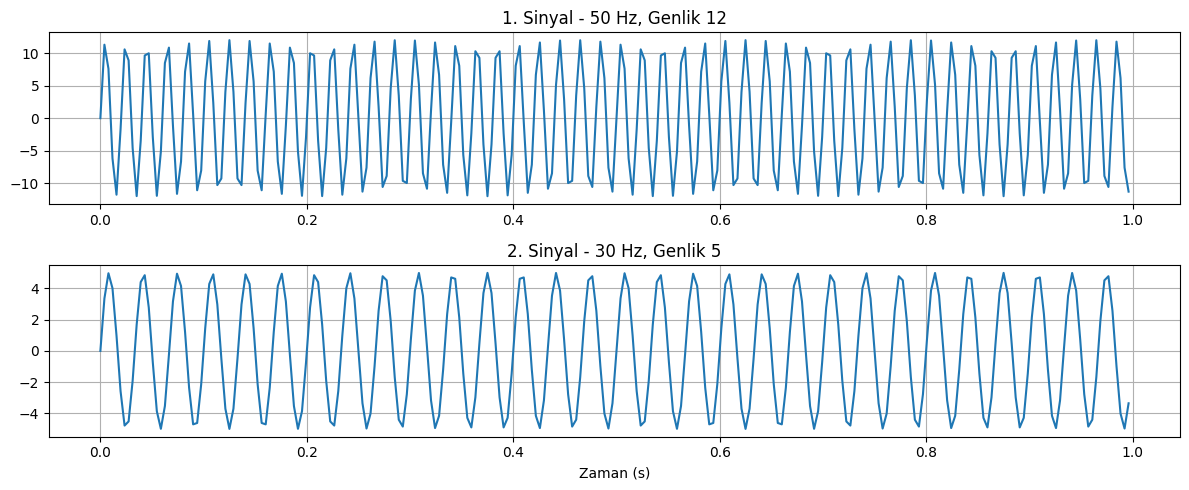

In [2]:
N = 256
fs = 256

t = np.arange(N) / fs

f1 = 50
A1 = 12

f2 = 30
A2 = 5

sinyal1 = A1 * np.sin(2 * np.pi * f1 * t)
sinyal2 = A2 * np.sin(2 * np.pi * f2 * t)

plt.figure(figsize=(12, 5))

plt.subplot(2, 1, 1)
plt.plot(t, sinyal1)
plt.title("1. Sinyal - 50 Hz, Genlik 12")
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(t, sinyal2)
plt.title("2. Sinyal - 30 Hz, Genlik 5")
plt.xlabel("Zaman (s)")
plt.grid(True)

plt.tight_layout()
plt.show()

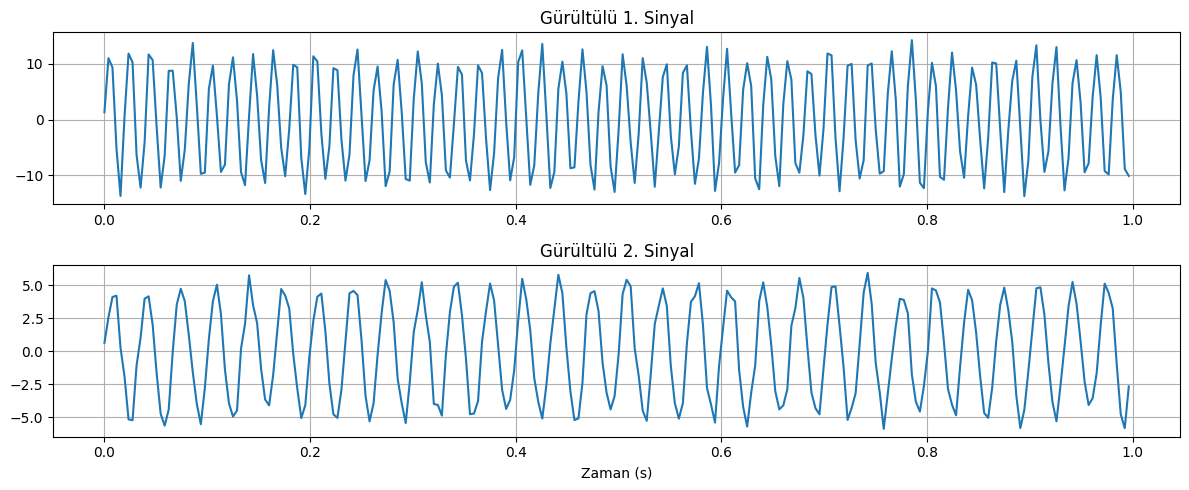

In [3]:
rng = np.random.default_rng(42)

gurultu_orani = 0.2

gurultu1 = rng.uniform(
    -A1 * gurultu_orani,
    A1 * gurultu_orani,
    N
)

gurultu2 = rng.uniform(
    -A2 * gurultu_orani,
    A2 * gurultu_orani,
    N
)

gurultulu1 = sinyal1 + gurultu1
gurultulu2 = sinyal2 + gurultu2

plt.figure(figsize=(12, 5))

plt.subplot(2, 1, 1)
plt.plot(t, gurultulu1)
plt.title("Gürültülü 1. Sinyal")
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(t, gurultulu2)
plt.title("Gürültülü 2. Sinyal")
plt.xlabel("Zaman (s)")
plt.grid(True)

plt.tight_layout()
plt.show()

In [4]:
def dft_hesapla(vektor):

    N = len(vektor)
    harmonikler = np.zeros(N, dtype=complex)
    n = np.arange(N)

    for k in range(N):
        harmonikler[k] = np.sum(
            vektor * np.exp(-2j * np.pi * k * n / N)
        )

    return harmonikler

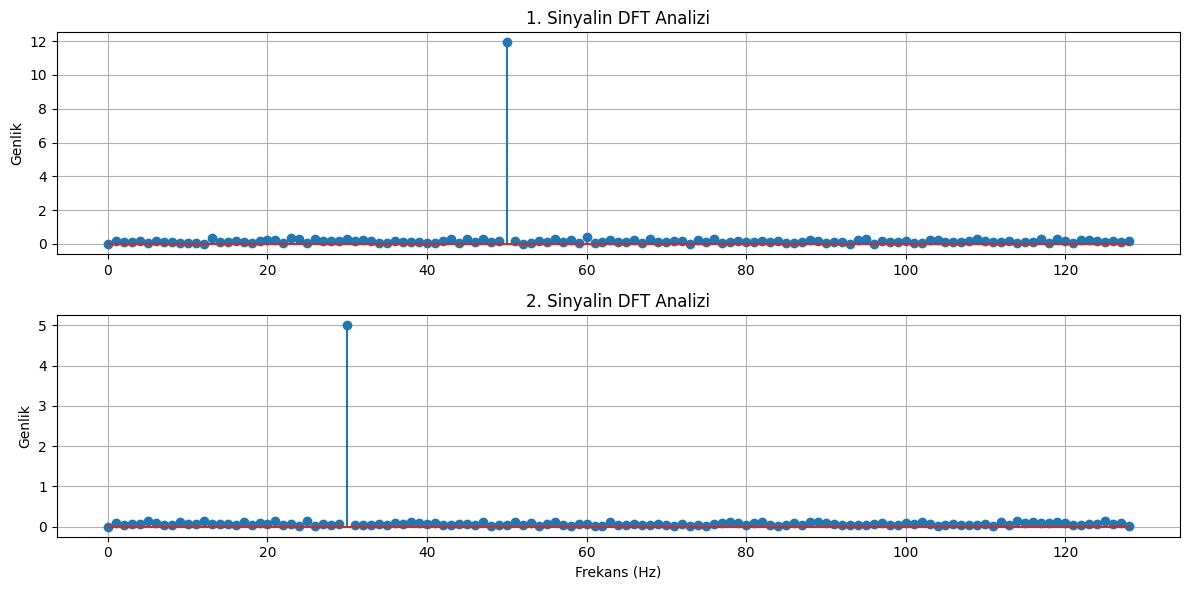

In [5]:
dft1 = dft_hesapla(gurultulu1)
dft2 = dft_hesapla(gurultulu2)

frekanslar = np.arange(N // 2 + 1) * fs / N

genlik1 = np.abs(dft1[:N // 2 + 1]) / N
genlik2 = np.abs(dft2[:N // 2 + 1]) / N

genlik1[1:-1] *= 2
genlik2[1:-1] *= 2

plt.figure(figsize=(12, 6))

plt.subplot(2, 1, 1)
plt.stem(frekanslar, genlik1)
plt.title("1. Sinyalin DFT Analizi")
plt.ylabel("Genlik")
plt.grid(True)

plt.subplot(2, 1, 2)
plt.stem(frekanslar, genlik2)
plt.title("2. Sinyalin DFT Analizi")
plt.xlabel("Frekans (Hz)")
plt.ylabel("Genlik")
plt.grid(True)

plt.tight_layout()
plt.savefig("odev35_ayri_dft.png", dpi=200)
plt.show()

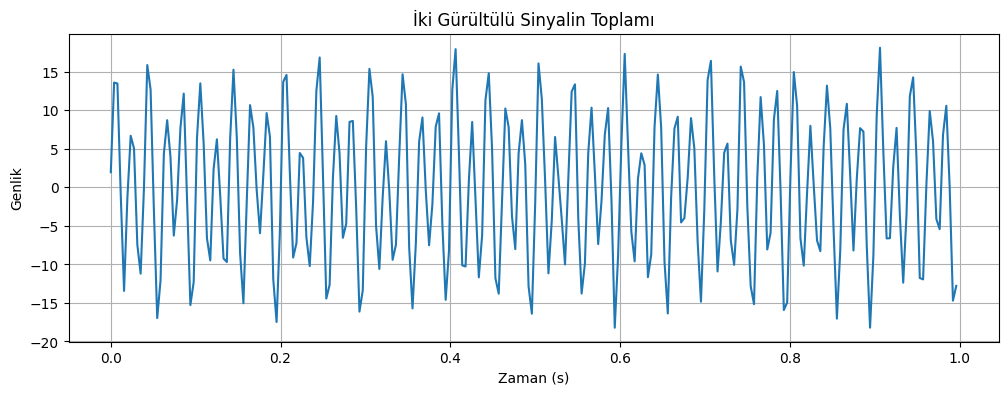

In [6]:
toplam_sinyal = gurultulu1 + gurultulu2

plt.figure(figsize=(12, 4))

plt.plot(t, toplam_sinyal)

plt.title("İki Gürültülü Sinyalin Toplamı")
plt.xlabel("Zaman (s)")
plt.ylabel("Genlik")
plt.grid(True)

plt.savefig("odev35_toplam_sinyal.png", dpi=200)
plt.show()

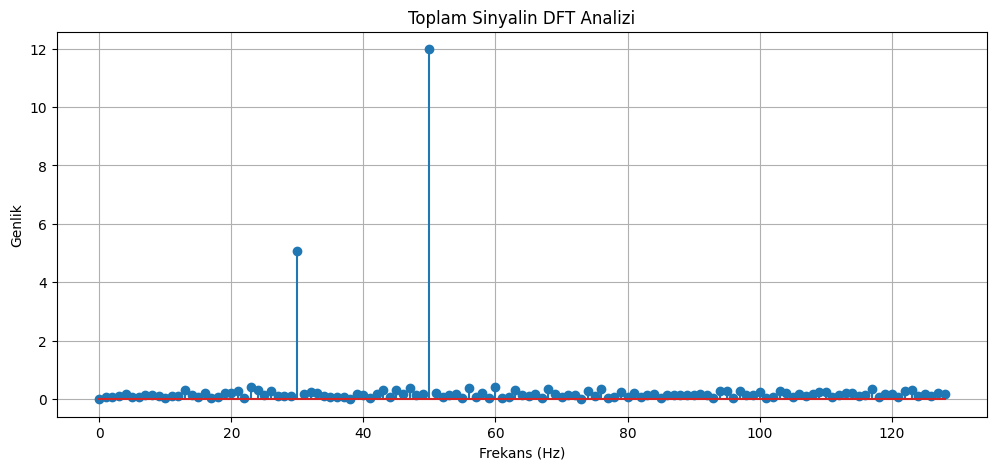

In [7]:
dft_toplam = dft_hesapla(toplam_sinyal)

genlik_toplam = np.abs(
    dft_toplam[:N // 2 + 1]
) / N

genlik_toplam[1:-1] *= 2

plt.figure(figsize=(12, 5))

plt.stem(frekanslar, genlik_toplam)

plt.title("Toplam Sinyalin DFT Analizi")
plt.xlabel("Frekans (Hz)")
plt.ylabel("Genlik")
plt.grid(True)

plt.savefig("odev35_toplam_dft.png", dpi=200)
plt.show()

In [8]:
indeksler = np.argsort(genlik_toplam[1:])[-2:] + 1

indeksler = indeksler[np.argsort(frekanslar[indeksler])]

print("Toplam sinyaldeki baskın frekanslar:")

for i in indeksler:
    print(
        f"Frekans: {frekanslar[i]:.1f} Hz, "
        f"Genlik: {genlik_toplam[i]:.3f}"
    )

Toplam sinyaldeki baskın frekanslar:
Frekans: 30.0 Hz, Genlik: 5.086
Frekans: 50.0 Hz, Genlik: 11.978


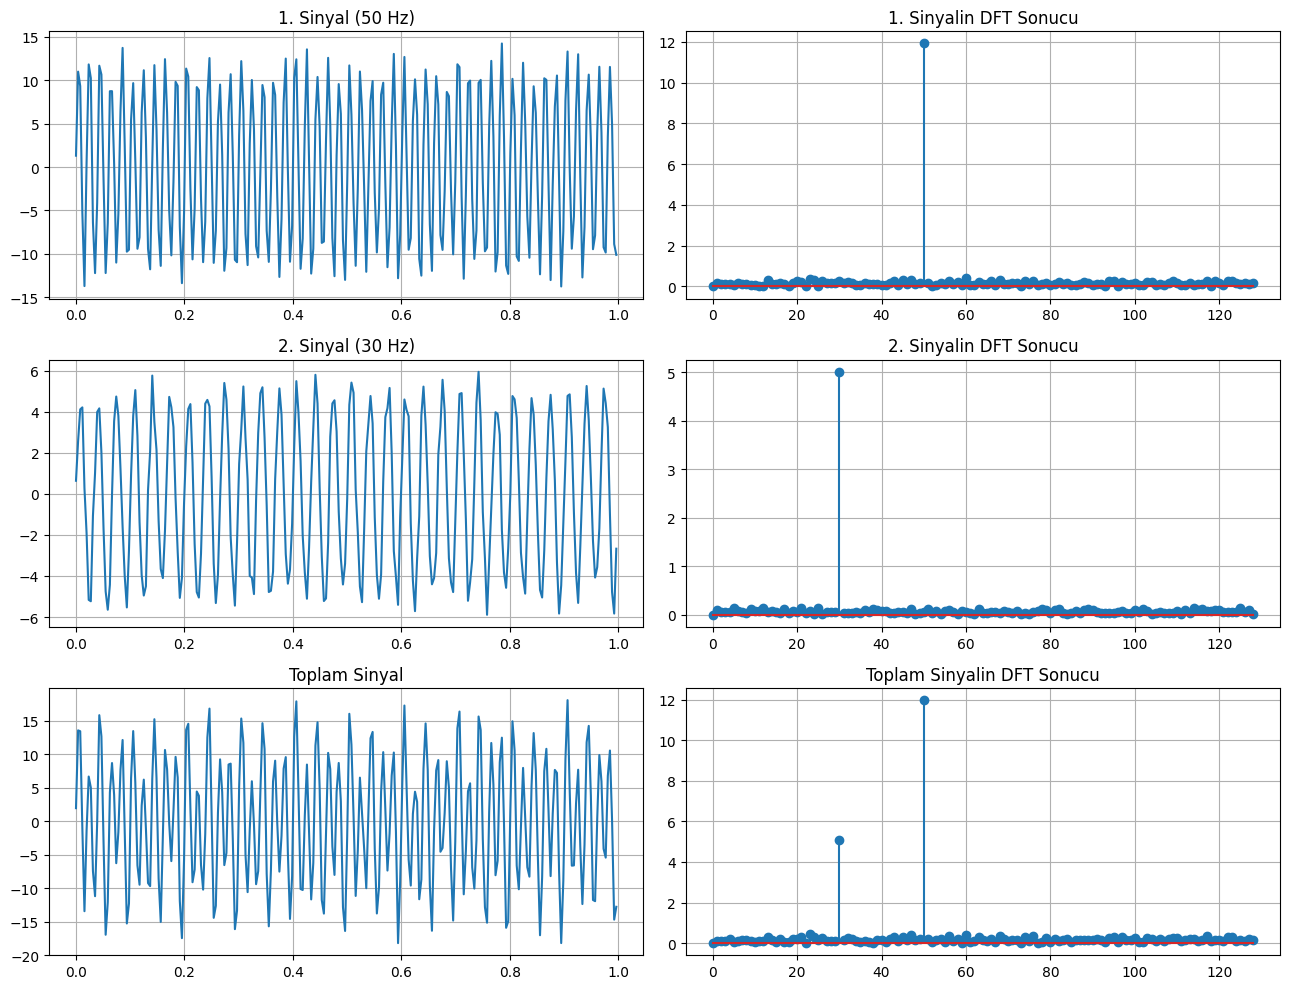

In [9]:
plt.figure(figsize=(13, 10))

plt.subplot(3, 2, 1)
plt.plot(t, gurultulu1)
plt.title("1. Sinyal (50 Hz)")
plt.grid(True)

plt.subplot(3, 2, 2)
plt.stem(frekanslar, genlik1)
plt.title("1. Sinyalin DFT Sonucu")
plt.grid(True)

plt.subplot(3, 2, 3)
plt.plot(t, gurultulu2)
plt.title("2. Sinyal (30 Hz)")
plt.grid(True)

plt.subplot(3, 2, 4)
plt.stem(frekanslar, genlik2)
plt.title("2. Sinyalin DFT Sonucu")
plt.grid(True)

plt.subplot(3, 2, 5)
plt.plot(t, toplam_sinyal)
plt.title("Toplam Sinyal")
plt.grid(True)

plt.subplot(3, 2, 6)
plt.stem(frekanslar, genlik_toplam)
plt.title("Toplam Sinyalin DFT Sonucu")
plt.grid(True)

plt.tight_layout()
plt.savefig("odev35_karsilastirma.png", dpi=200)
plt.show()

### Sonuç ve Yorum

Bu çalışmada frekansları 50 Hz ve 30 Hz, genlikleri ise sırasıyla 12 ve 5 olan iki sinüs sinyali oluşturulmuş ve her iki sinyale de rastgele gürültü eklenmiştir.

Sinyallere ayrı ayrı DFT uygulandığında, frekans spektrumlarında 50 Hz ve 30 Hz değerlerinde belirgin tepeler oluşması beklenmektedir. İki sinyal toplandığında ise zaman uzayında daha karmaşık bir dalga elde edilmektedir. Toplam sinyalin DFT analizinde her iki frekans bileşeninin de görülmesi, DFT'nin birleşik sinyallerin frekans içeriğini belirlemede kullanılabildiğini göstermektedir.